# TP1 - Visión por Computadora I

## Parte 1: White Patch

In [3]:
# Librerías
import cv2 as cv                 # OpenCV: leer y procesar imágenes
import numpy as np               # cuentas con matrices
import matplotlib.pyplot as plt  # gráficos
import glob                      # listar los archivos de una carpeta
%matplotlib inline

In [4]:
def white_patch(img_bgr):
    """Corrige el color suponiendo que lo más brillante de cada canal es el 'blanco' de la escena."""
    # Pasamos a decimales: así no perdemos precisión ni nos pasamos de 255 a mitad de cuenta
    img = img_bgr.astype(np.float32)
    # Máximo de cada canal (B, G, R) en toda la imagen -> 3 números
    maximos = img.reshape(-1, 3).max(axis=0)
    # Escalamos cada canal por 255 / su máximo: el máximo de cada canal pasa a valer 255
    corregida = img * (255.0 / maximos)
    # Volvemos a enteros 0-255 para poder mostrarla
    return np.clip(corregida, 0, 255).astype(np.uint8), maximos

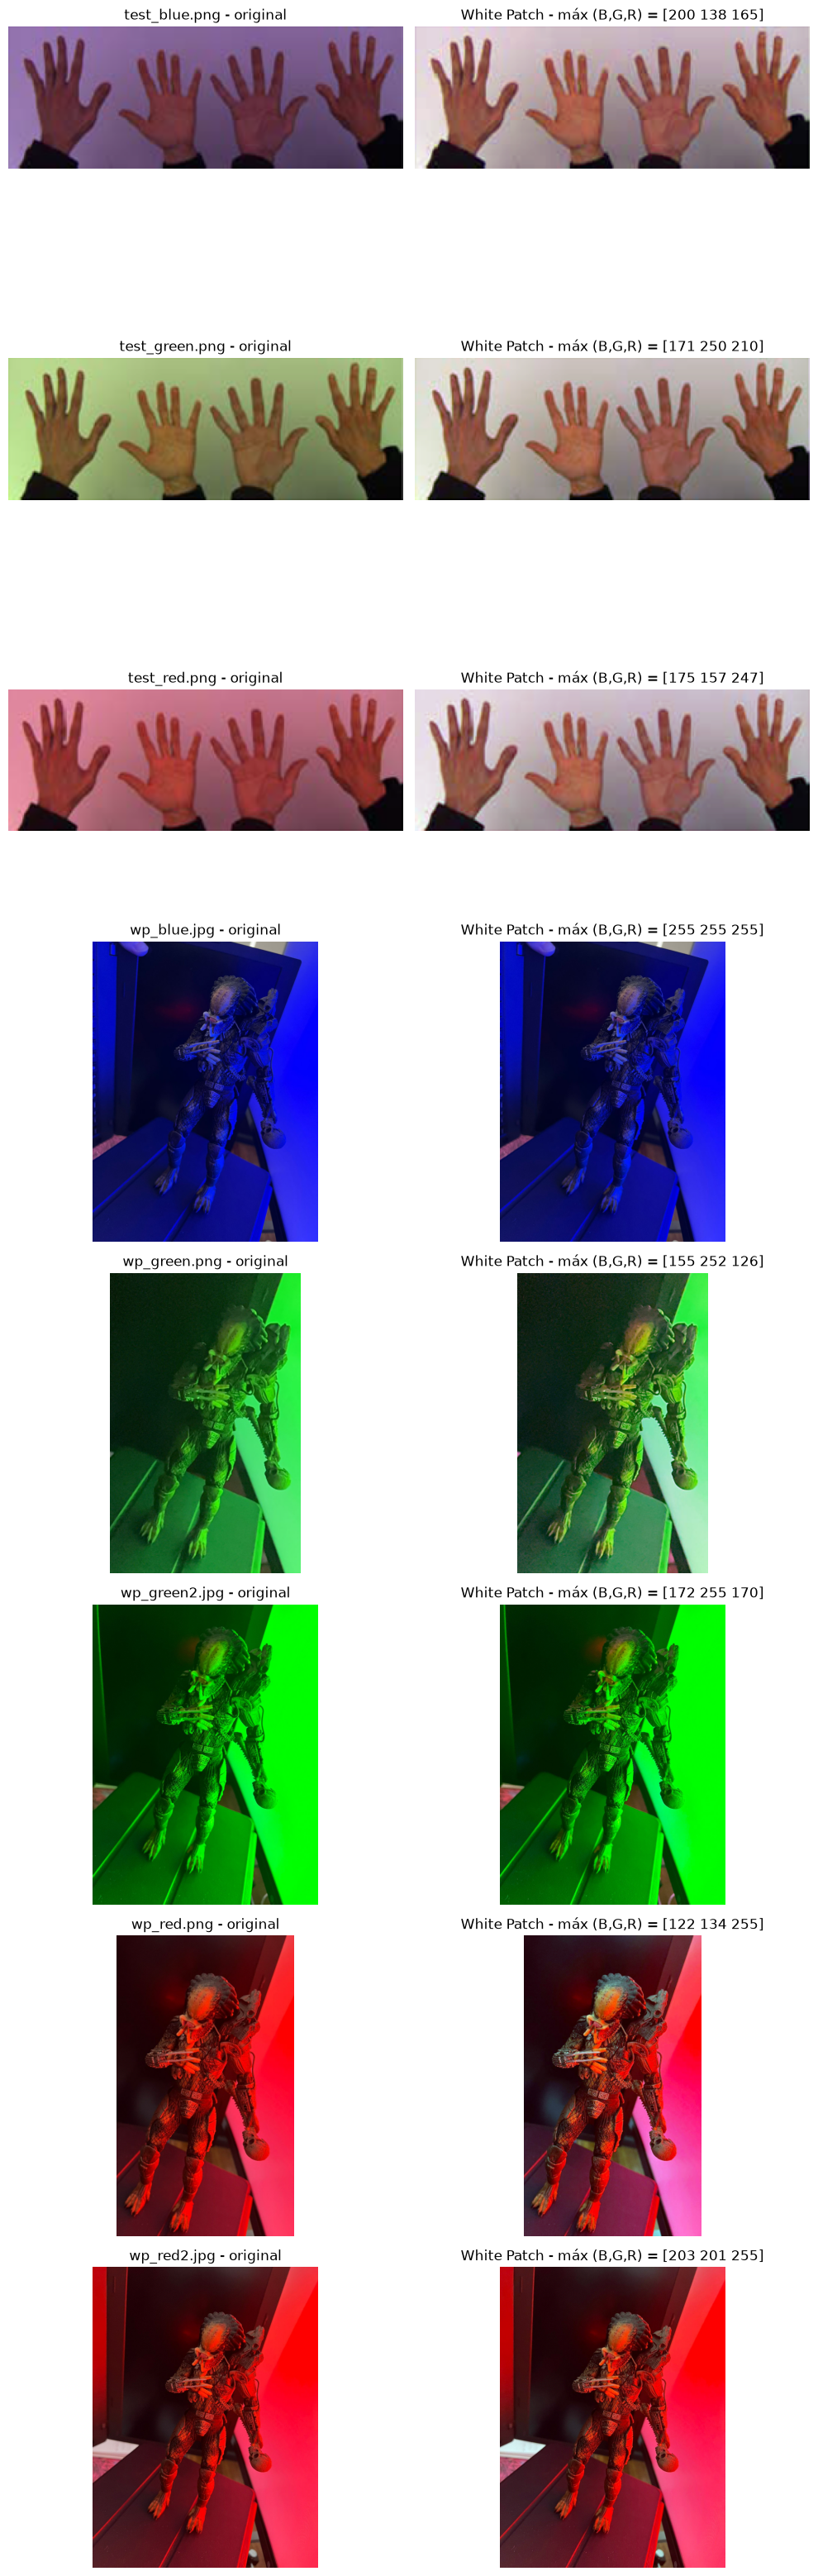

In [5]:
# Todas las imágenes de la carpeta white_patch, en orden alfabético
archivos = sorted(glob.glob('white_patch/*'))

# Una fila por imagen: a la izquierda la original, a la derecha la corregida
fig, ejes = plt.subplots(len(archivos), 2, figsize=(10, 4 * len(archivos)))

for i, archivo in enumerate(archivos):
    img = cv.imread(archivo)                 # OpenCV lee en orden BGR
    corregida, maximos = white_patch(img)

    # Matplotlib espera RGB: convertimos solo para mostrar
    ejes[i, 0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ejes[i, 0].set_title(f'{archivo.split("/")[-1]} - original')

    ejes[i, 1].imshow(cv.cvtColor(corregida, cv.COLOR_BGR2RGB))
    ejes[i, 1].set_title(f'White Patch - máx (B,G,R) = {maximos.astype(int)}')

    # Sacamos los ejes con números, que en una foto no aportan
    ejes[i, 0].axis('off')
    ejes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### Análisis de fallas de White Patch

White Patch toma el valor máximo de cada canal como el "blanco" de la escena y escala cada canal para llevarlo a 255.

**Funciona bien** en las imágenes `test_*`: ningún canal está saturado y la corrección elimina buena parte de la dominante de color.

**Falla 1 - Saturación:** en `wp_blue.jpg` los máximos son (255, 255, 255). El factor de corrección da 255/255 = 1 y la imagen queda igual.

**Falla 2 - Canales sin información:** en `wp_green2.jpg` el azul y el rojo valen en promedio ≈ 4. Multiplicarlos no recupera color que la cámara no captó, y la imagen sigue verde.

**Falla 3 - Sensibilidad a pocos píxeles:** en `wp_blue.jpg` solo 3 píxeles de 1.920.000 están en 255 en los tres canales, y alcanzan para anular toda la corrección. Al usar el máximo, un reflejo o un píxel ruidoso decide el resultado.


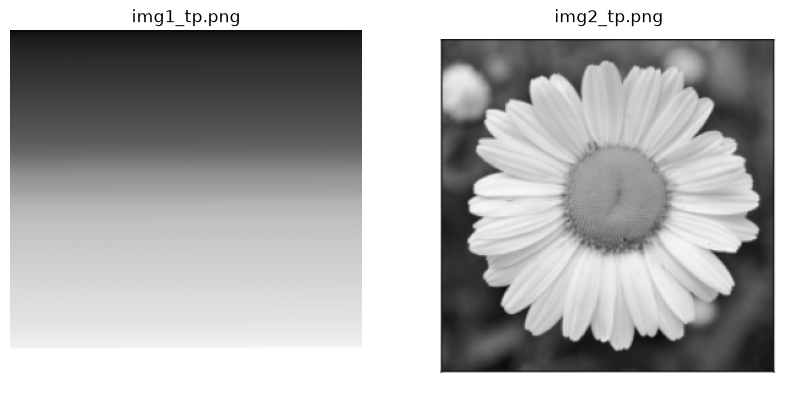

In [6]:
# Leemos las dos imágenes directamente en escala de grises (un solo número por píxel, 0 a 255)
img1 = cv.imread('img1_tp.png', cv.IMREAD_GRAYSCALE)
img2 = cv.imread('img2_tp.png', cv.IMREAD_GRAYSCALE)

# Las mostramos una al lado de la otra
fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
ejes[0].imshow(img1, cmap='gray', vmin=0, vmax=255)  # vmin/vmax: 0 = negro, 255 = blanco, sin reescalar
ejes[0].set_title('img1_tp.png')
ejes[1].imshow(img2, cmap='gray', vmin=0, vmax=255)
ejes[1].set_title('img2_tp.png')
ejes[0].axis('off')
ejes[1].axis('off')
plt.show()


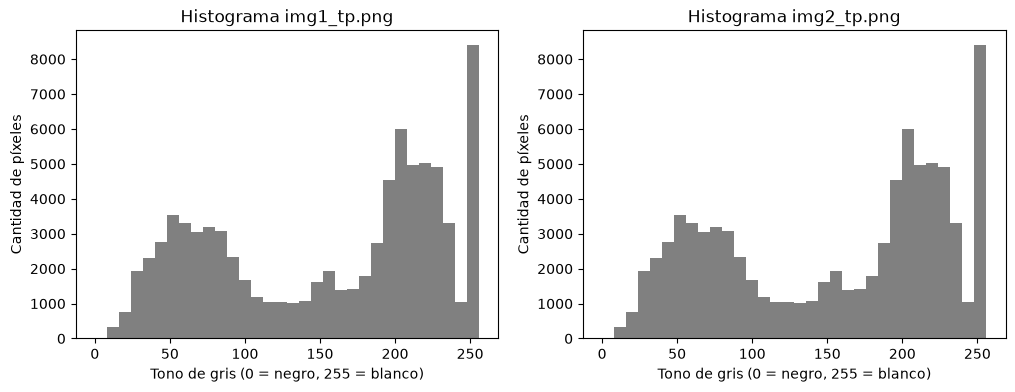

In [7]:
# Cantidad de cajones: 32 (cada uno agrupa 8 tonos de gris)
bins = 32

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

# .ravel() aplana la imagen a una lista de píxeles; hist cuenta cuántos caen en cada cajón
# range=(0, 256): mismos cajones para las dos imágenes, así se pueden comparar
ejes[0].hist(img1.ravel(), bins=bins, range=(0, 256), color='gray')
ejes[0].set_title('Histograma img1_tp.png')
ejes[1].hist(img2.ravel(), bins=bins, range=(0, 256), color='gray')
ejes[1].set_title('Histograma img2_tp.png')

for eje in ejes:
    eje.set_xlabel('Tono de gris (0 = negro, 255 = blanco)')
    eje.set_ylabel('Cantidad de píxeles')

plt.show()


### Análisis de histogramas

Las dos imágenes son muy distintas (un degradé y una flor), pero sus histogramas son **idénticos**: tienen la misma cantidad de píxeles de cada tono de gris, solo que ubicados en otro lugar.

**¿Sirven los histogramas como features para clasificación o detección?**

- **Solos, no.** El histograma cuenta tonos pero descarta *dónde* están, y por eso pierde la forma y la estructura de la imagen. Un modelo que solo vea el histograma confundiría estas dos imágenes.
- **Para detección, menos todavía**, porque detectar es encontrar *dónde* está un objeto, y esa información el histograma no la tiene.
- **Como feature complementaria sí pueden servir**, cuando la clase depende del brillo o del contraste general (día/noche, sobreexposición) o combinados con información espacial (por ejemplo, histogramas por regiones de la imagen).
